# Load data and compute missing metrics & rolling means

In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

COLUMNS_TO_READ = [
    'frame',
    'ACCELERATION#wcentroid (cm/s2)',
    "SPEED#wcentroid (cm/s)",
    'X (cm)',
    'Y (cm)',
    'time',
]

In [9]:
df.columns

Index(['frame', 'ACCELERATION#pcentroid (cm/s2)',
       'ACCELERATION#wcentroid (cm/s2)', 'ANGLE', 'ANGULAR_A#centroid',
       'ANGULAR_V#centroid', 'AX', 'AY', 'BORDER_DISTANCE#pcentroid (cm)',
       'MIDLINE_OFFSET', 'SPEED#wcentroid (cm/s)', 'SPEED#pcentroid (cm/s)',
       'SPEED (cm/s)', 'VX (cm/s)', 'VY (cm/s)', 'X#wcentroid (cm)', 'X (cm)',
       'Y#wcentroid (cm)', 'Y (cm)', 'detection_p', 'frame.1',
       'midline_length', 'midline_segment_length', 'midline_x', 'midline_y',
       'missing', 'normalized_midline', 'num_pixels', 'time', 'timestamp',
       'visual_identification_p', 'River', 'pH', 'Trial', 'Individual',
       'ANGULAR_A', 'ANGULAR_V', 'radius', 'Date', 'Camera', 'Population',
       'Exposure Tank', 'Video start time (approximate) (Clock  time)',
       'Fish in time (Clock time)', 'Skin extract injection (Clock time)',
       'Skin extract injection (Video run time)',
       'Visual disturbance  (Clock time)',
       'Visual disturbance (Video run time)',

In [10]:
def compute_radius(x, y, x_center, y_center):
    """Computes the distance between (x, y) and (x_center, y_center)."""
    return ((x - x_center) ** 2 + (y - y_center) ** 2) ** 0.5

assert compute_radius(0, 0, 0, 0) == 0
assert compute_radius(10, 100, 10, 100) == 0
assert compute_radius(100, 0, 0, 0) == 100
assert compute_radius(0, 100, 0, 0) == 100
assert compute_radius(1, 1, 0, 0) == 2 ** 0.5
assert compute_radius(3, 3, 2, 2) == 2 ** 0.5

In [11]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(
                        DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv",
                        usecols=COLUMNS_TO_READ,
                    )
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except Exception as e:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")
                    print(e)

df = pd.concat(dfs, ignore_index=True)
del(dfs)


# Manual border distance computation
CENTER_X = 2000
CENTER_Y = 1000
df["radius"] = compute_radius(df["X (cm)"], df["Y (cm)"], CENTER_X, CENTER_Y)

# # Throws out data points with infinite x or y (missing locations)
df = df[~(np.isinf(df["X (cm)"]) | np.isinf(df["Y (cm)"]))]

# # Throws out anomolous points with radius > a cutoff.
df = df[~((df["radius"] > 1300) & (df["time"] < 60))]

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
df["skin_extract_injection_time"] = df["time"] - df["skin_extract_injection_seconds"]
df["visual_disturbance_time"] = df["time"] - df["visual_disturbance_seconds"]

,Date,River,Trial,Camera,pH,Population,Exposure Tank,Video start time (approximate) (Clock time),Fish in time (Clock time),Skin extract injection (Clock time),Skin extract injection (Video run time),Visual disturbance (Clock time),Visual disturbance (Video run time),File name 1 for Issac,File name 2 for Issac,Notes
0,10/1/2024,Green,1,1,2,Green,A,9:47:37,?,10:11:22,25:15,10:17:23,29:48,pH2 Trial 1.mp4,NaN,Start recording 1:30 late
1,10/1/2024,Green,1,2,3,Green,A,9:47:37,?,10:11:22,25:15,10:17:33,29:59,pH3 Trial 1.mp4,NaN,NaN
2,10/1/2024,Green,1,3,1,Green,A,9:47:37,?,10:11:22,25:15,10:17:26,29:52,pH1 Trial 1.mp4,NaN,NaN
3,10/1/2024,Green,2,1,2,Green,B,11:06:44,11:07:16,11:32:06,25:22,11:38:13,31:32,pH2 Trial 2a.mp4,pH2 Trial 2b.mp4,Fixing glare until~ min. 3
4,10/1/2024,Green,2,2,3,Green,B,11:06:44,11:07:06,11:32:06,25:22,11:38:20,31:39,pH3 Trial 2a.mp4,pH3 Trial 2b.mp4,Fixing glare until~ min. 3
5,10/1/2024,Green,2,3,1,Green,B,11:06:44,11:07:31,11:32:06,25:22,11:38:08,31:26,pH1 Trial 2a.mp4,pH1 Trial 2b.mp4,NaN
6,10/1/2024,Green,3,1,2,Green,A,12:19:32,12:20:09,12:45:24,25:52,12:51:30,32:02,pH2 Trial 3.mp4,NaN,Small fish with bad tail/little movement (excl...
7,10/1/2024,Green,3,2,3,Green,A,12:19:32,12:19:53,12:45:24,25:52,12:51:36,32:07,pH3 Trial 3.mp4,NaN,NaN
8,10/1/2024,Green,3,3,1,Green,A,12:19:32,12:19:51,12:45:24,25:52,12:51:25,31:56,pH1 Trial 3.mp4,NaN,NaN
9,10/1/2024,Green,4,1,2,Green,B,13:26:25,13:26:58,13:52:08,25:43,13:58:15,31:53,pH2 Trial 4.mp4,NaN,NaN


In [12]:
# Radius correction
PH_TO_X_Y_RADIUS = {
    #   x center, y center, radius
    1: (3840/2 + 75, 2160/2, 1284),
    2: (3840/2 + 144, 2160/2, 1184),
    3: (3840/2 + 30, 2160/2 + 20, 1284),
}

# We don't actually want to save these columns to the dataframe, they're unnecessarily big.
# But doing it like this is in theory faster.
df["center x"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][0], axis=1)
df["center y"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][1], axis=1)
df["radius length"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][2], axis=1)

df["radius"] = compute_radius(
    df["X (cm)"],
    df["Y (cm)"],
    df["center x"],
    df["center y"],
) / df["radius length"]

df["X"] = (df["X (cm)"] - df["center x"])/df["radius length"]
df["Y"] = (df["Y (cm)"] - df["center y"])/df["radius length"]

In [13]:
# Rescale kinematics by radius length
df["speed"] = df["SPEED#wcentroid (cm/s)"] / df["radius length"]
df["acceleration"] = df["ACCELERATION#wcentroid (cm/s2)"]

In [14]:
COLUMNS_TO_KEEP = [
    "River", "pH", "Trial", "Individual",
    "time",
    "radius",
    "acceleration", "speed",
    "skin_extract_injection_time",
    "visual_disturbance_time",
]
df = df[COLUMNS_TO_KEEP]

In [42]:
# Adds rolling means.
NAMES = [
    ("radius", "radius"),
    ("speed", "speed"),
    ("acceleration", "acceleration"),
    # ("pspeed", "SPEED#pcentroid (cm/s)"),
]
ROLLING_MEAN_FRAMES = [15]#, 60, 240]

for short_name, col_name in NAMES:
    for i in ROLLING_MEAN_FRAMES:
        print(f"\r{short_name} {i}", end="          ")
        df[f"{short_name}{i}"] = df.groupby(
            ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

acceleration 15          

# Look for startles

In [43]:
# Add 99th percentile here.
QUANTILES = [0.5, 0.9, 0.99]
COLUMNS = ["speed", "speed15", "acceleration"]
COLUMN_NAMES = ["River", "pH", "Trial", "Individual"]
for column in COLUMNS:
    for quantile in QUANTILES:
        COLUMN_NAMES.append(column + str(quantile))

data = []

for _name, group_df in df.groupby(["River", "pH", "Trial", "Individual"]):
    river, pH, trial, individual = _name
    

    row = [river, pH, trial, individual]

    for column in COLUMNS:
        for quantile in QUANTILES:
            row.append(group_df[column].quantile(quantile))
            

    data.append(row)



by_fish = pd.DataFrame(data, columns = COLUMN_NAMES)
# df = df.merge(by_trial_minute, on=["River", "pH", "Trial", "Individual"], how="left")
# del(by_trial_minute) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.

<Axes: xlabel='speed150.99', ylabel='Count'>

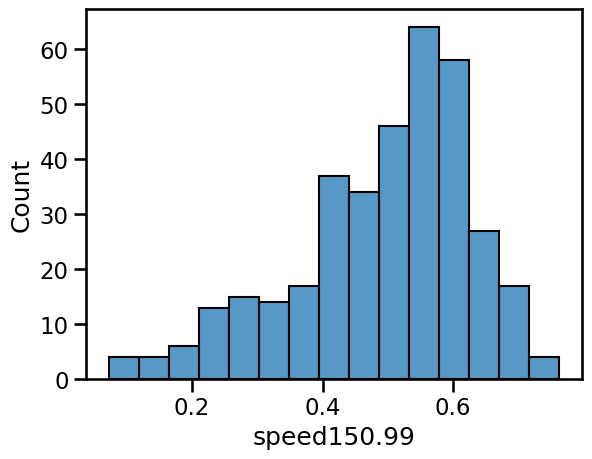

In [45]:
sns.histplot(data=by_fish, x="speed150.99")

In [17]:
df["speed"].quantile([0.5, 0.90, 0.99])

0.50    0.055202
0.90    0.251334
0.99    0.694881
Name: speed, dtype: float64

[None]

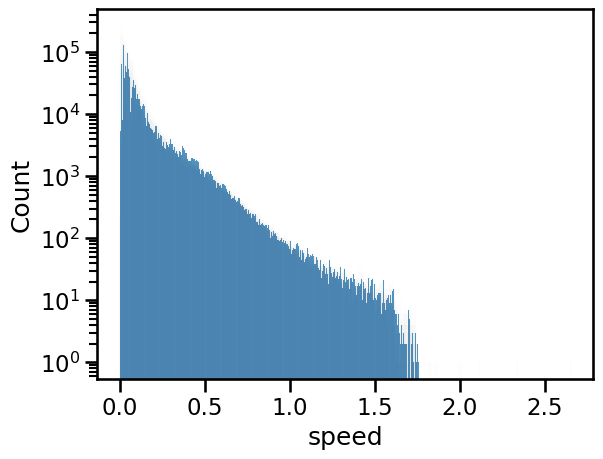

In [18]:
p = sns.histplot(df["speed"])
p.set(yscale="log")
# p.set(xscale="log")

In [47]:
df["startle"] = df["speed15"] > 0.5

In [48]:
# # Looking for startle starts

COLUMN_NAMES = ["River", "pH", "Trial", "Individual", "time"]

data = []

for _name, group_df in df.groupby(["River", "pH", "Trial", "Individual"]):
    river, pH, trial, individual = _name

    print(f"\r{river} {pH} {trial} {individual}             ", end="")

    in_startle = False
    for _, r in group_df.iterrows():
        if not in_startle:
            if r["startle"]:
                in_startle = True
                data.append([river, pH, trial, individual, r["time"]])

        else:
            if not r["startle"]:
                in_startle = False

startle_starts = pd.DataFrame(data, columns = COLUMN_NAMES)

startle_starts["startle_start"] = 1

df = df.merge(startle_starts, on=["River", "pH", "Trial", "Individual", "time"], how="left")
df["startle_start"] = df["startle_start"].fillna(0)

Skagit 3 10 5             

In [51]:
df = df.merge(startle_starts, on=["River", "pH", "Trial", "Individual", "time"], how="left")
df["startle_start"] = df["startle_start"].fillna(0)

In [52]:
# Adds rolling means.
NAMES = [
    ("startle_start", "startle_start"),
    # ("speed", "speed"),
    # ("acceleration", "acceleration"),
    # ("pspeed", "SPEED#pcentroid (cm/s)"),
]
ROLLING_MEAN_FRAMES = [15, 60, 240]

for short_name, col_name in NAMES:
    for i in ROLLING_MEAN_FRAMES:
        print(f"\r{short_name} {i}", end="          ")
        df[f"{short_name}{i}"] = df.groupby(
            ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

startle_start 240          

In [58]:
VARIABLES = [
    "speed",
    "speed15",
    "acceleration",
    "acceleration15",
    "startle_start",
    "startle_start15",
    "startle_start60",
    "startle_start240",
    # "speed0.99",
    # "acceleration0.99",
    # "X (cm)",
    # "Y (cm)",
    # "radius",
    # "meanneighbordist",
    # "minneighbordist",
]

# First 10 minutes
first_10 = df[
    (df["time"] > 60) &
    (df["time"] < 60 * 10)]

# 5 minutes before and after skin extract injection.
SKIN_EXTRACT_BEFORE = a, b = (-60 * 1, 0)
SKIN_EXTRACT_AFTER = c, d = (60 * 4, 60 * 5)
skin_extract_before = df[
    ((df["skin_extract_injection_time"] >= a) & (df["skin_extract_injection_time"] <= b))]
skin_extract_after = df[
     ((df["skin_extract_injection_time"] >= c) & (df["skin_extract_injection_time"] <= d))]

# visual disturbance.
VISUAL_DISTURBANCE_BEFORE = a, b = (-60 * 1, 0)
VISUAL_DISTURBANCE_AFTER_SHORT = c, d = (0, 2)
VISUAL_DISTURBANCE_AFTER_LONG = e, f = (2, 30)

visual_disturbance_before = df[
    (df["visual_disturbance_time"] >= a) & (df["visual_disturbance_time"] <= b)]
visual_disturbance_after_short = df[
     ((df["visual_disturbance_time"] >= c) & (df["visual_disturbance_time"] <= d))]
visual_disturbance_after_long = df[
     ((df["visual_disturbance_time"] >= e) & (df["visual_disturbance_time"] <= f))]


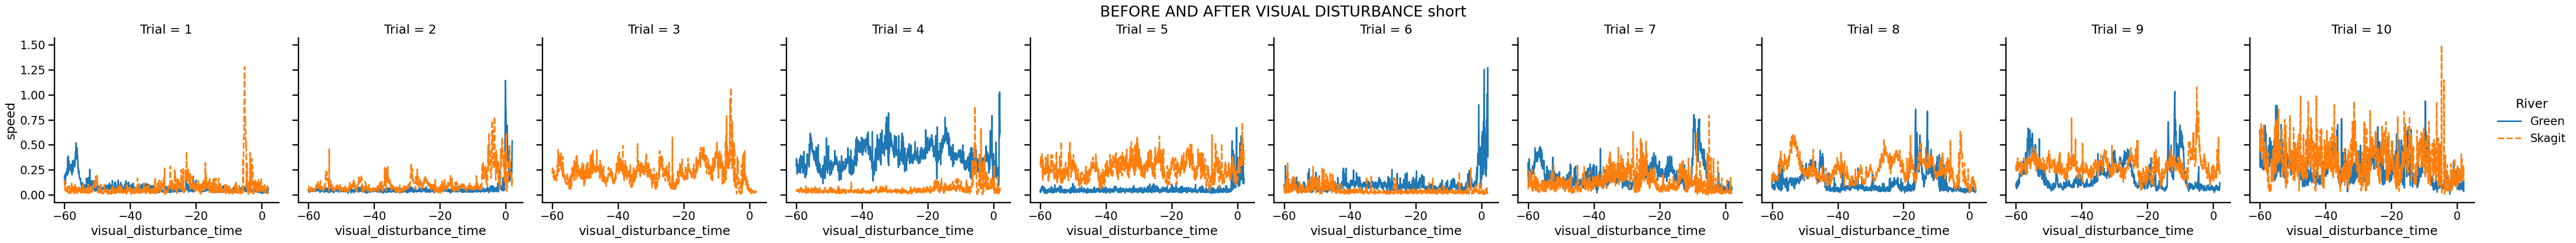

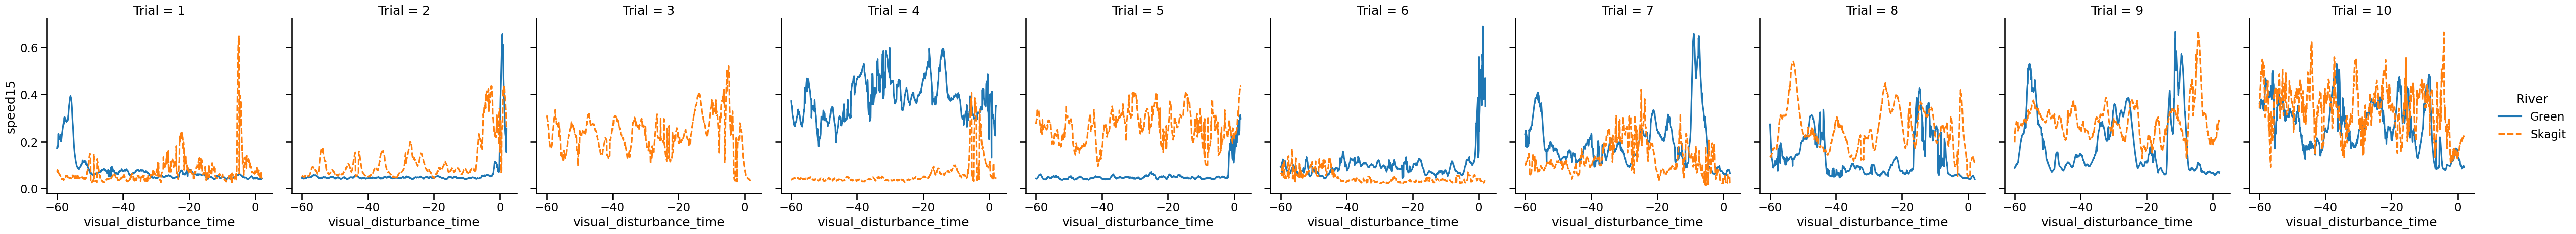

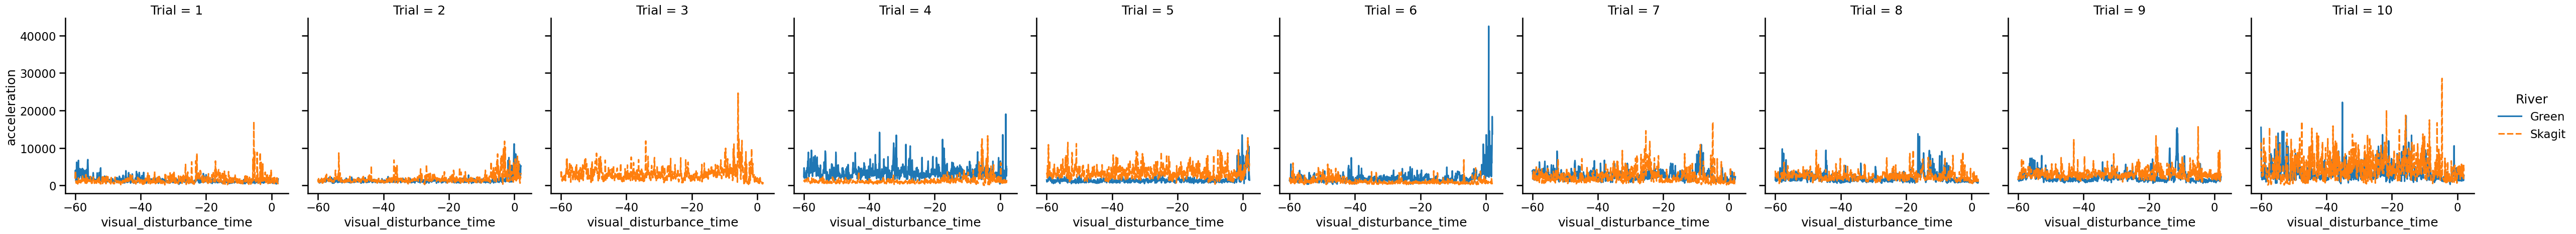

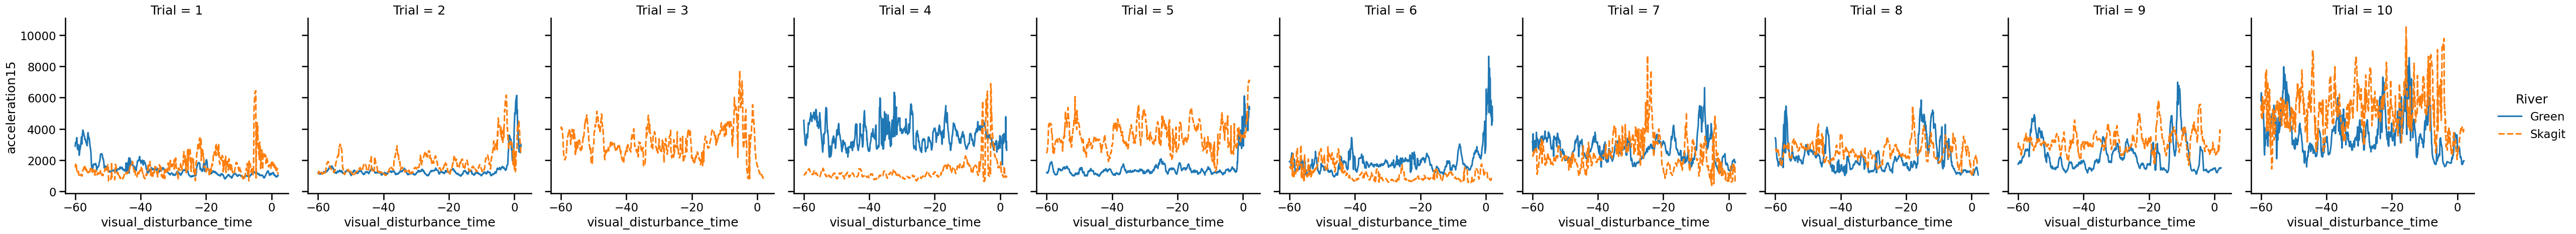

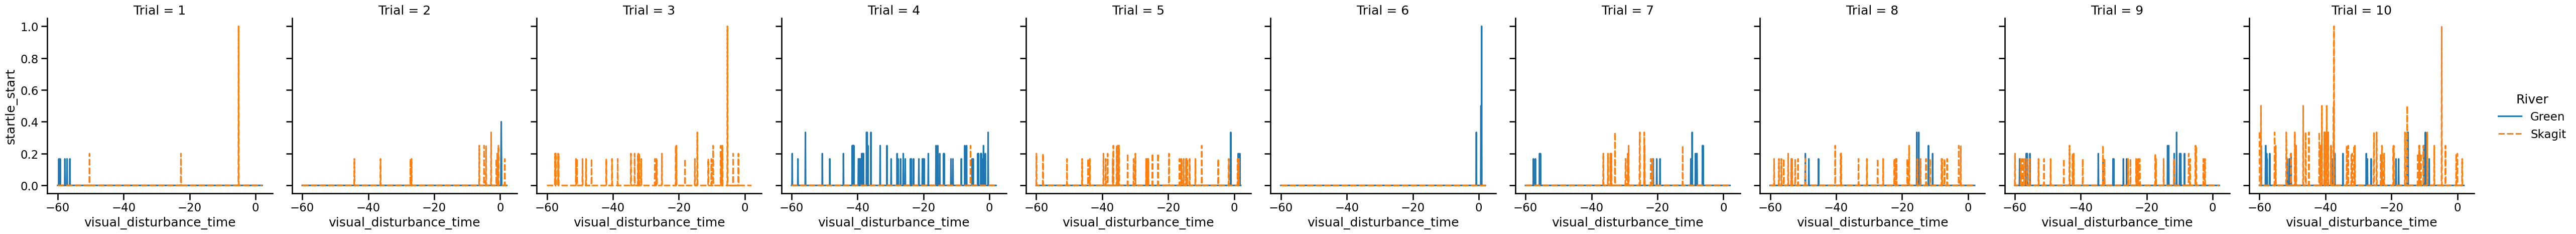

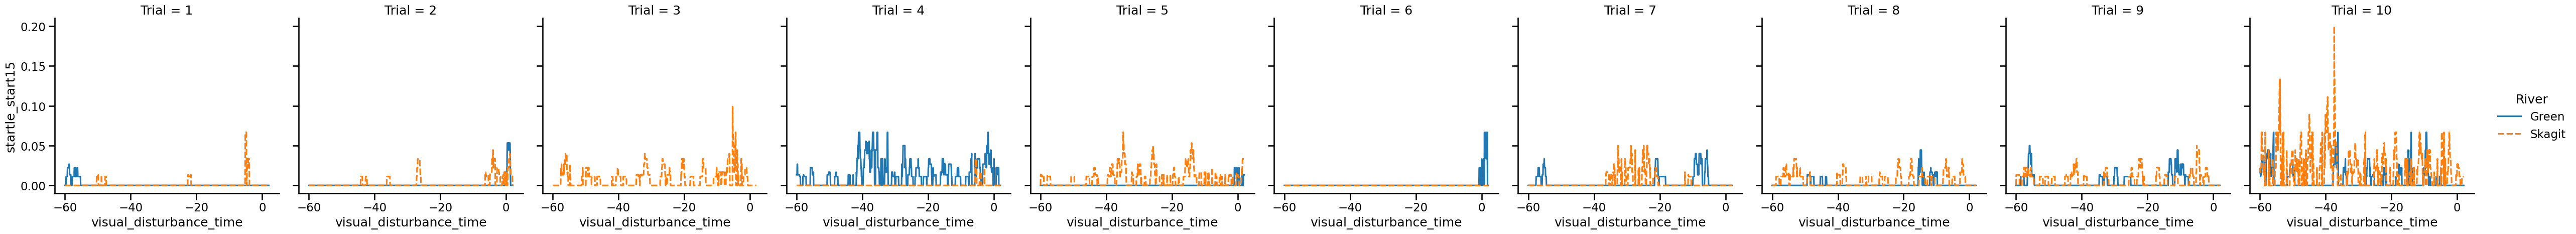

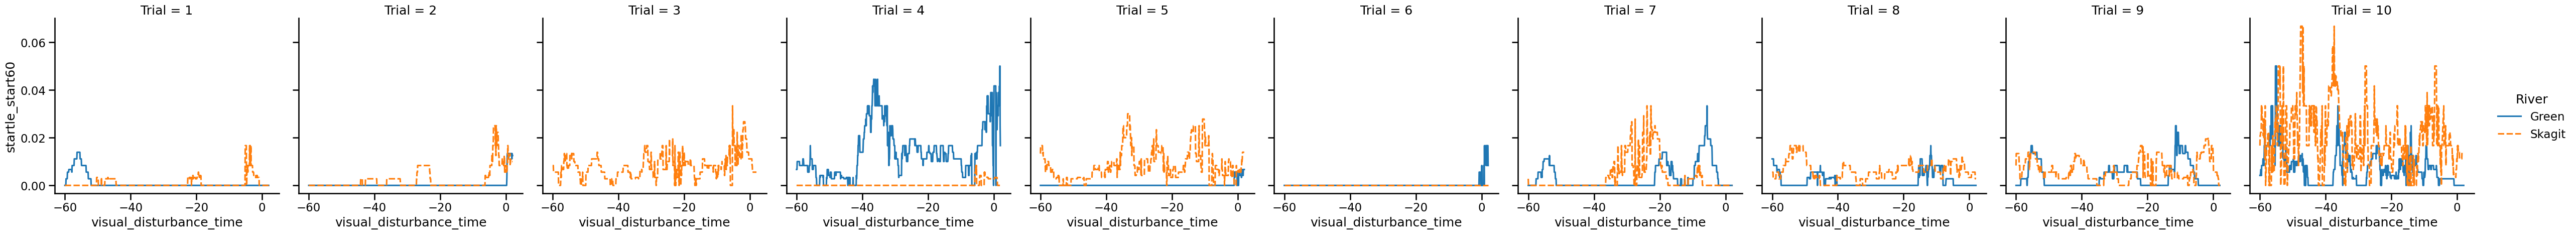

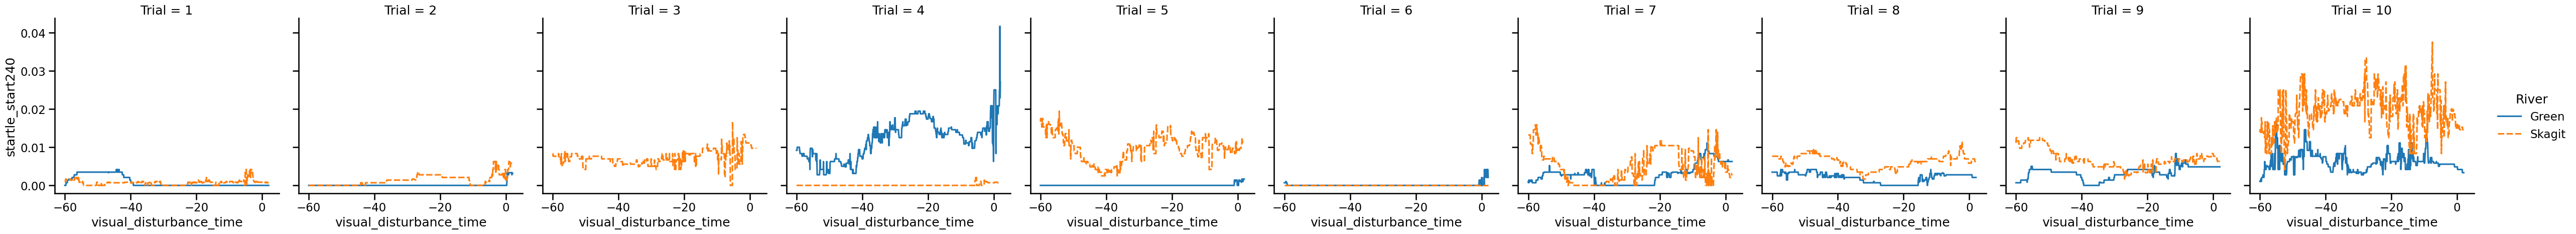

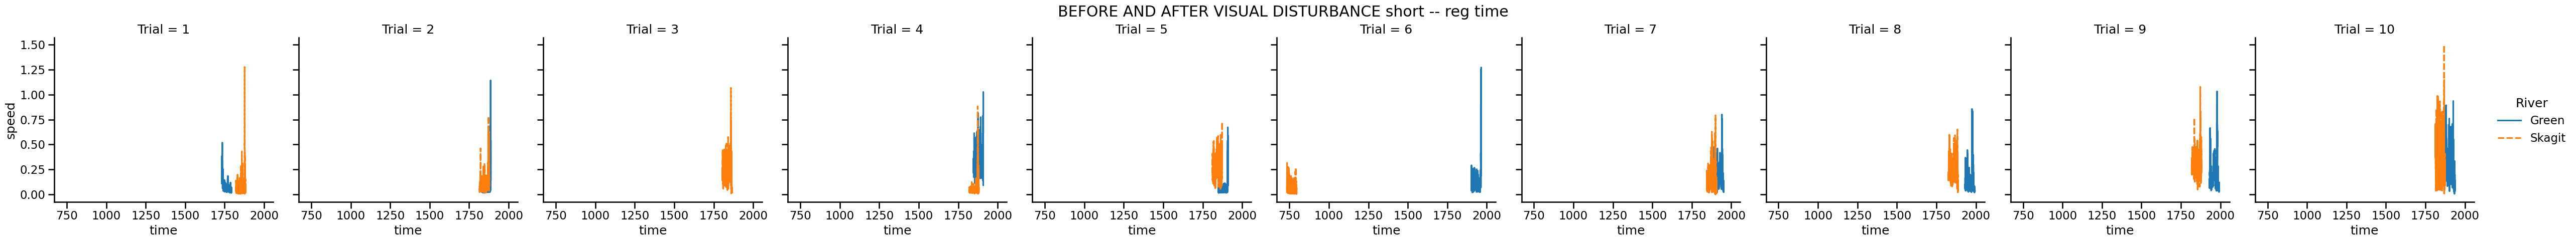

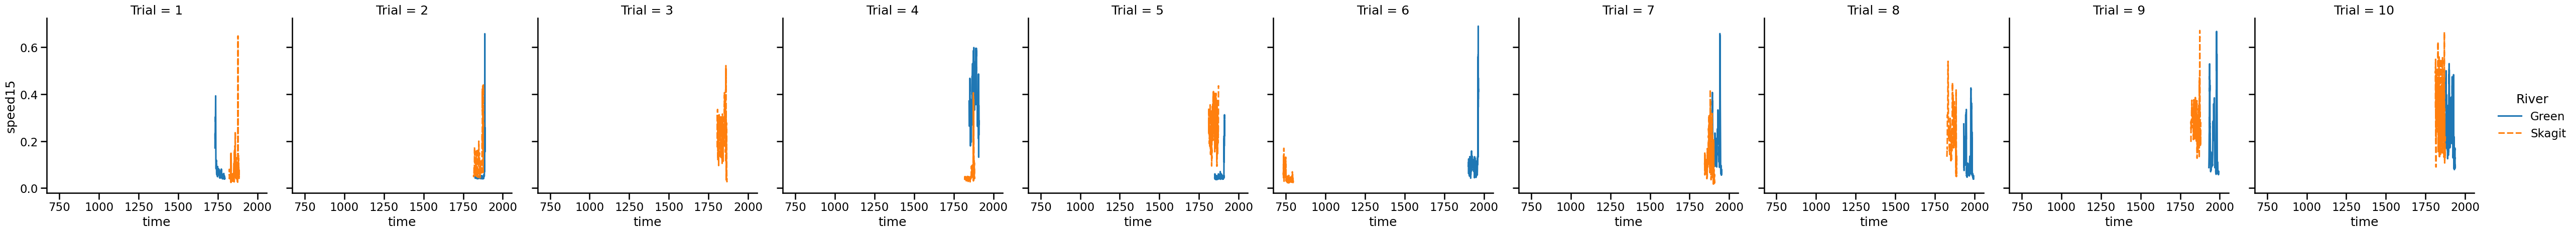

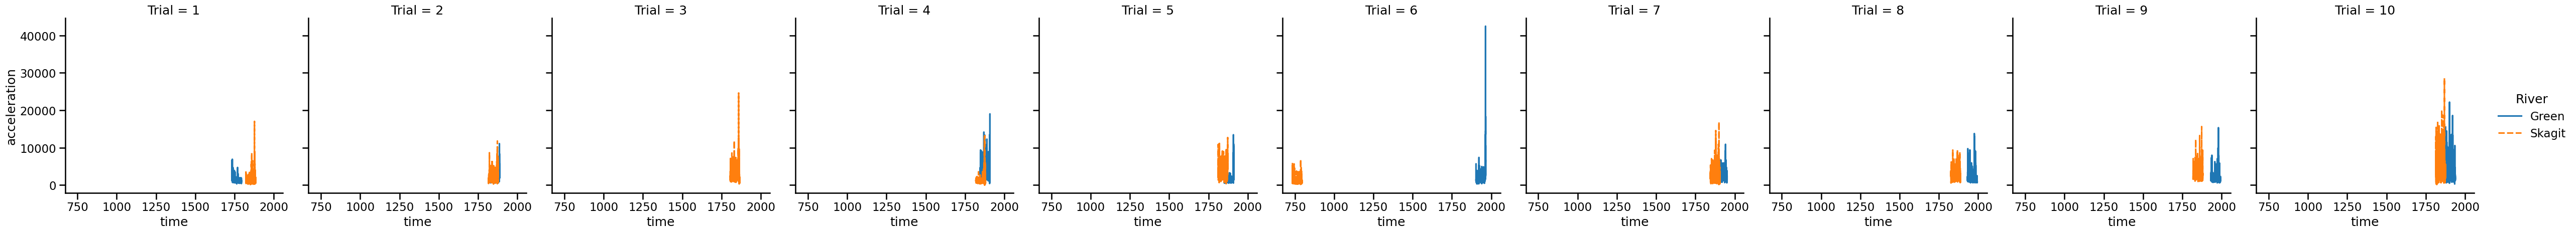

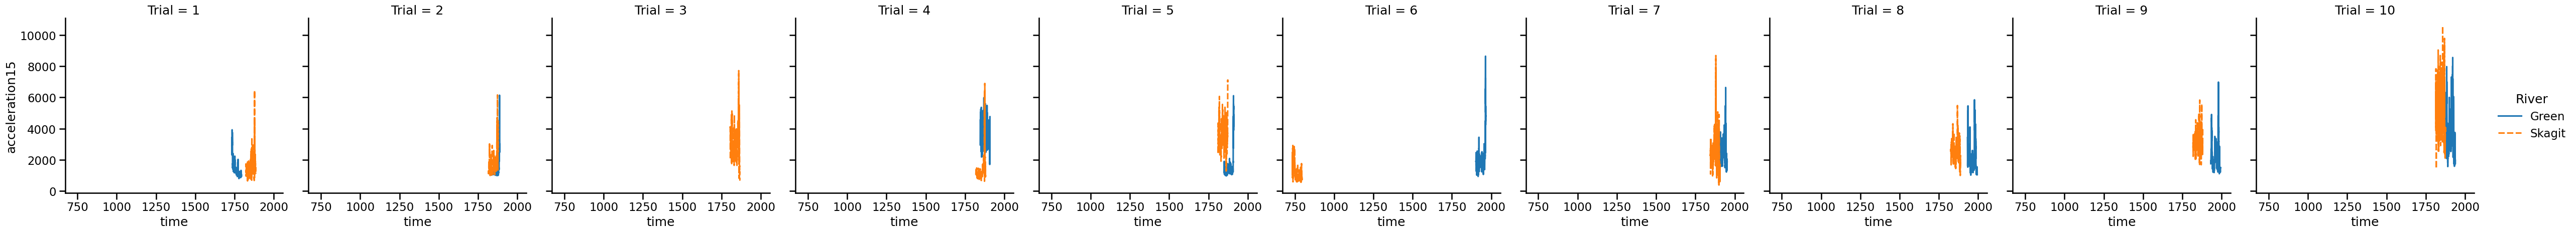

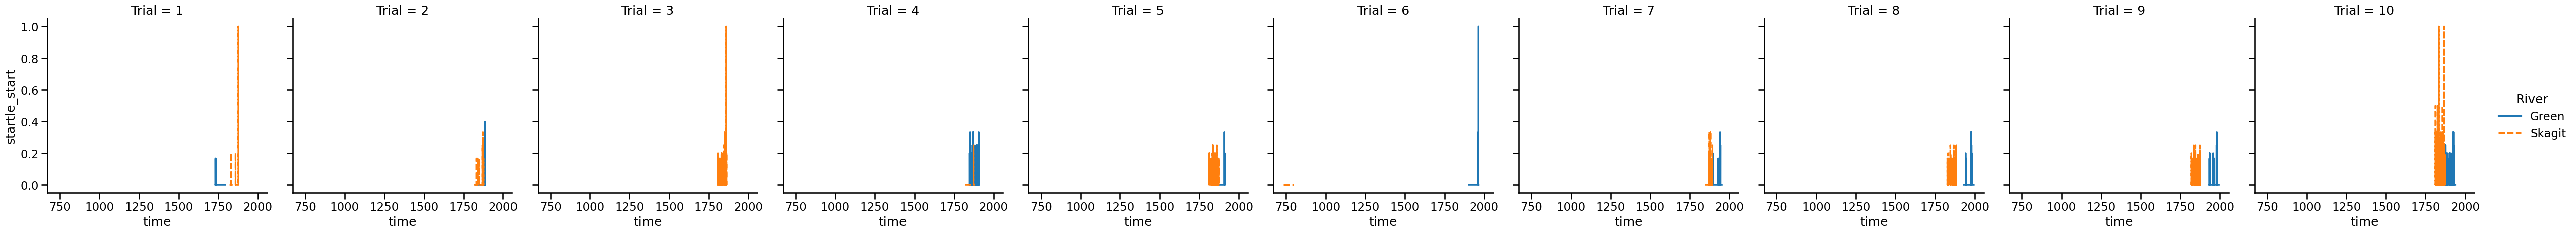

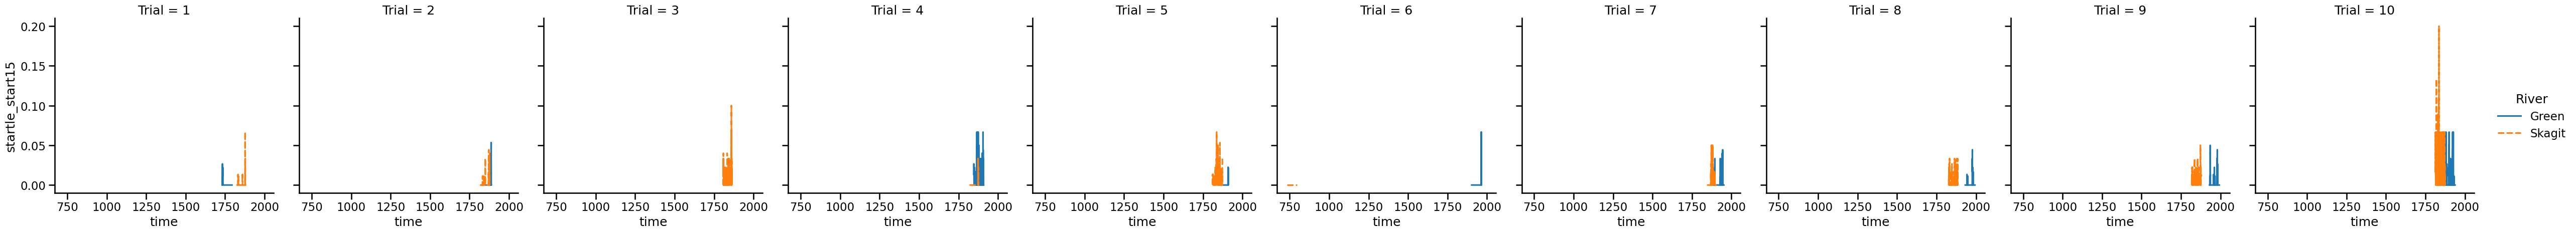

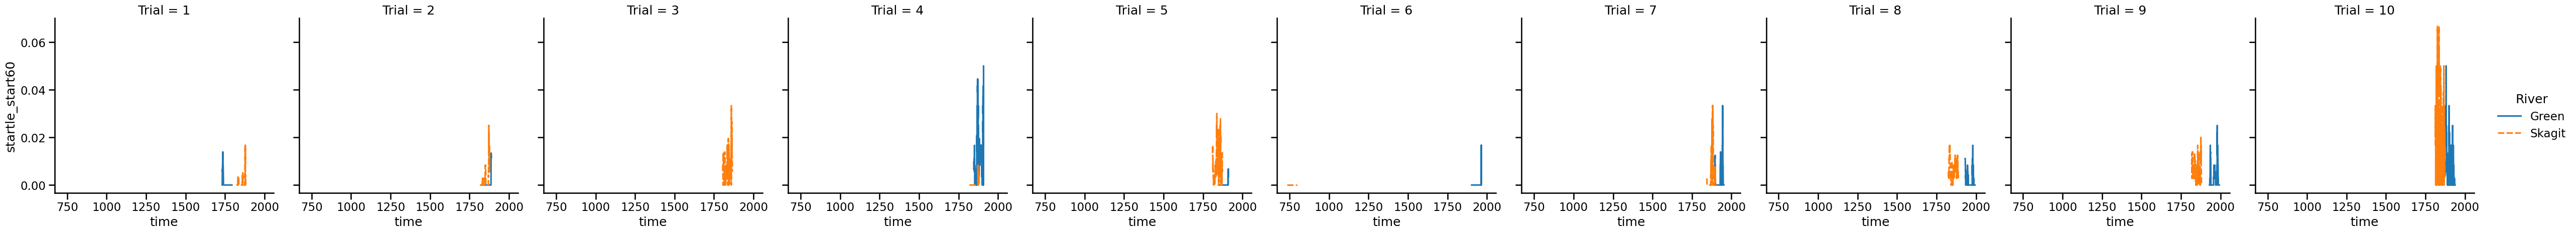

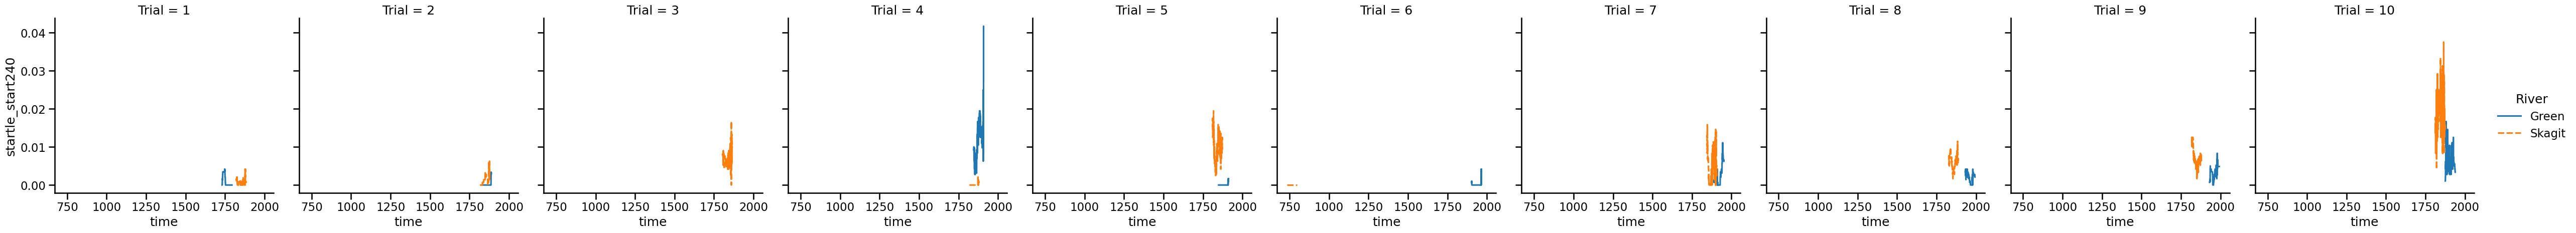

In [71]:
for _df, title, time_var in [
    # (first_10, "FIRST 10 MINUTES", "time"),
    # (pd.concat([skin_extract_before, skin_extract_after]),
    #      "BEFORE AND AFTER SKIN EXTRACT INJECTION",  "skin_extract_injection_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_short]),
         "BEFORE AND AFTER VISUAL DISTURBANCE short", "visual_disturbance_time"),
    # (pd.concat([visual_disturbance_before, visual_disturbance_after_long]),
    #  "BEFORE AND AFTER VISUAL DISTURBANCE long", "visual_disturbance_time"),
]:


    for i, var in enumerate(VARIABLES):
        p = sns.relplot(data=_df[_df["pH"] == 1], x=time_var, y=var, kind="line", col="Trial", style="River", hue="River", errorbar=None)
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)


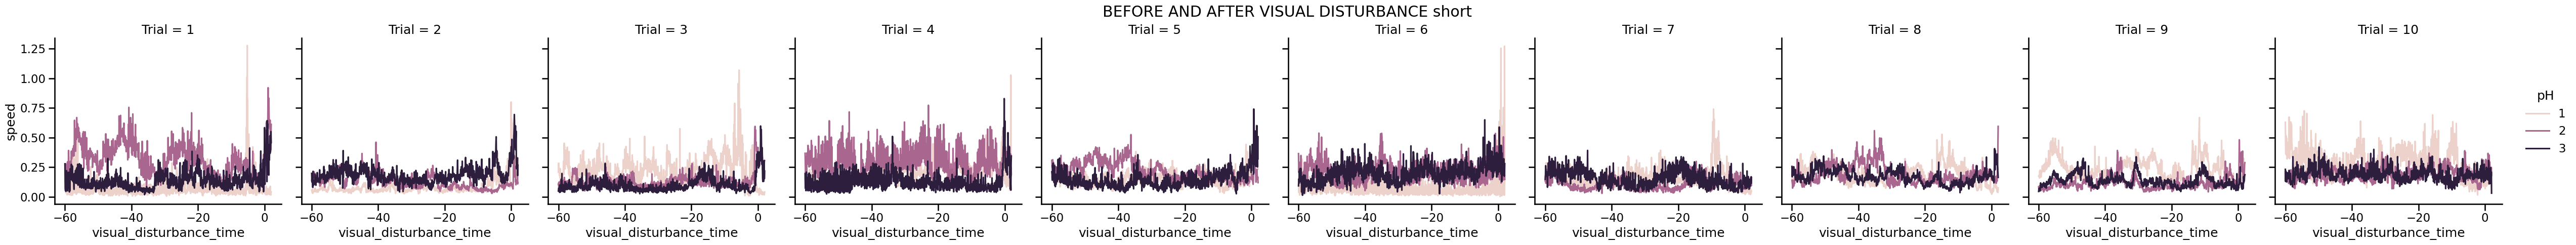

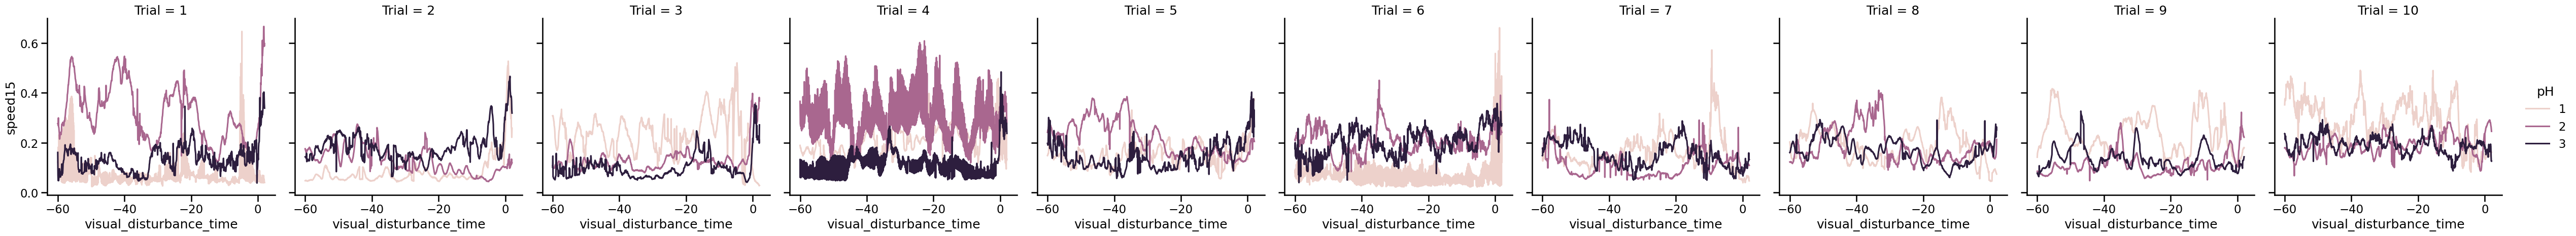

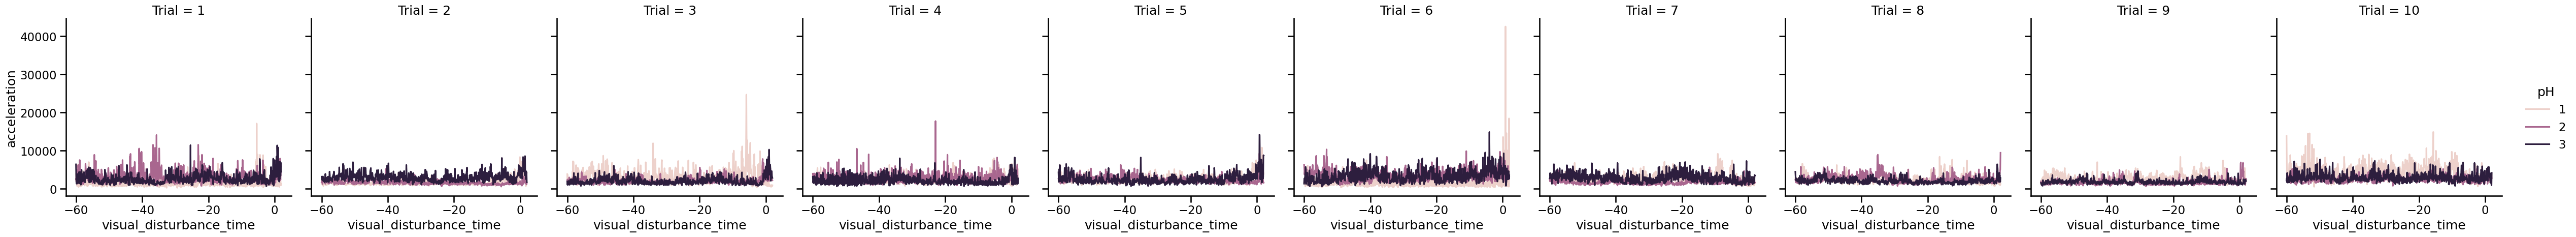

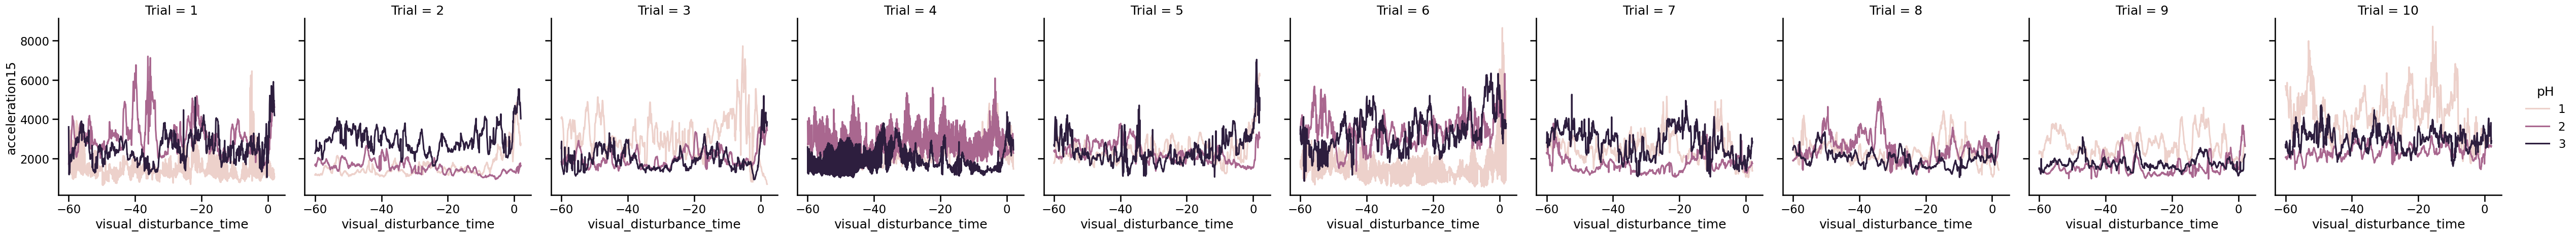

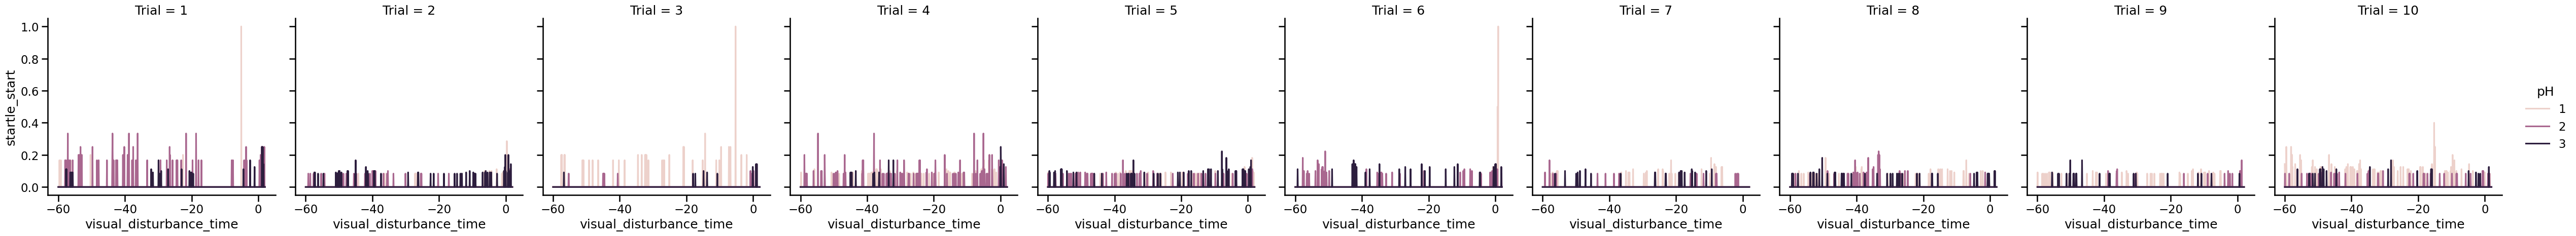

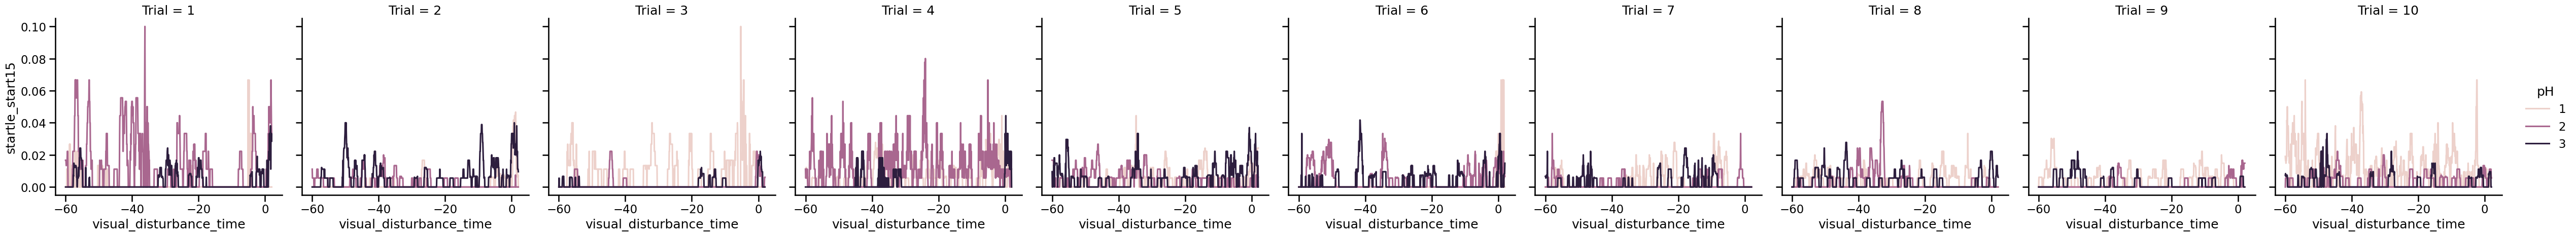

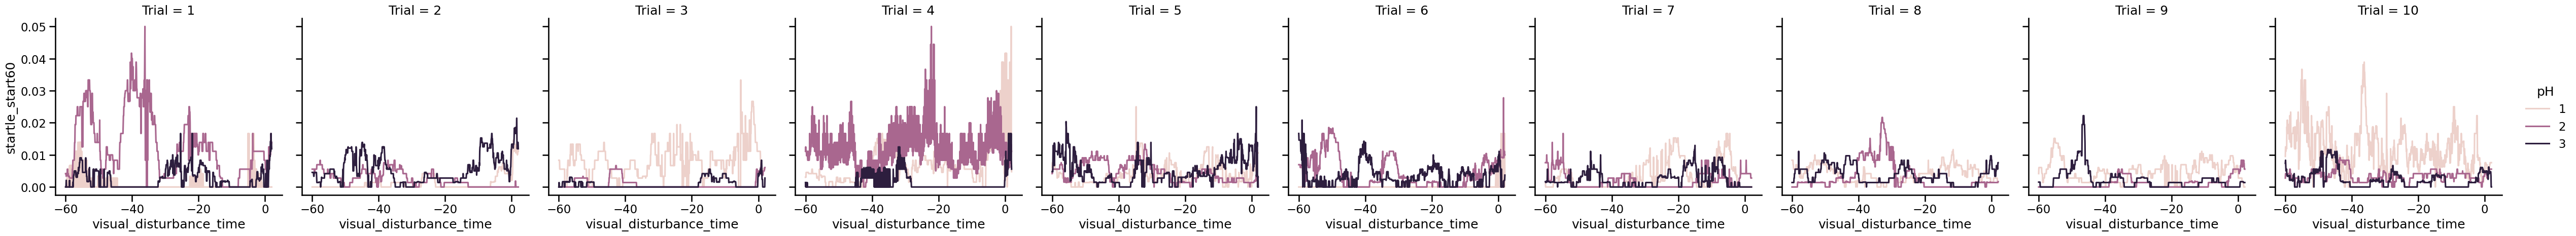

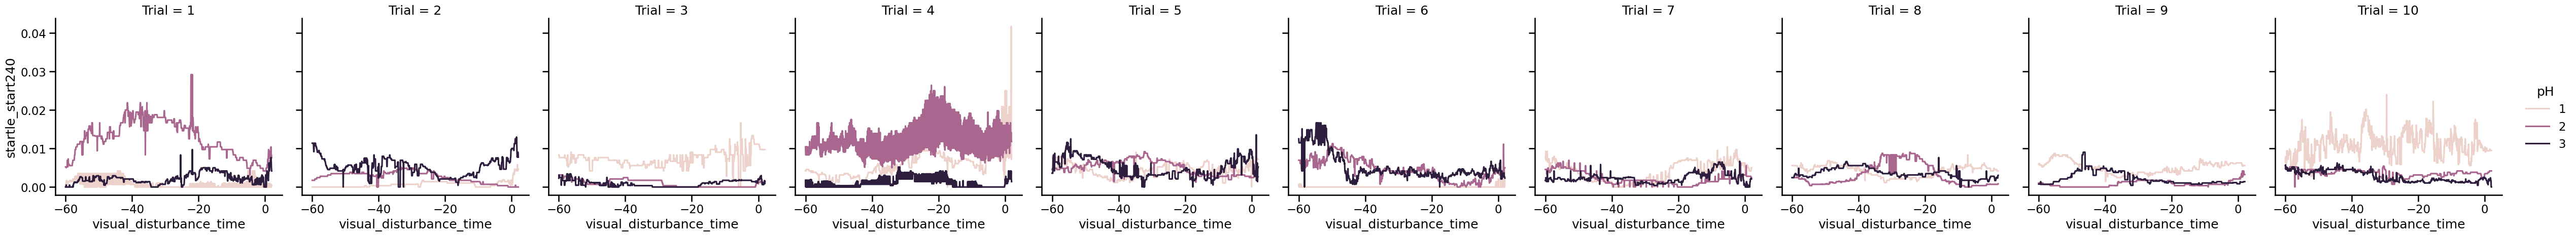

In [91]:
for _df, title, time_var in [
    # (first_10, "FIRST 10 MINUTES", "time"),
    # (pd.concat([skin_extract_before, skin_extract_after]),
    #      "BEFORE AND AFTER SKIN EXTRACT INJECTION",  "skin_extract_injection_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_short]),
         "BEFORE AND AFTER VISUAL DISTURBANCE short", "visual_disturbance_time"),
    # (pd.concat([visual_disturbance_before, visual_disturbance_after_long]),
    #  "BEFORE AND AFTER VISUAL DISTURBANCE long", "visual_disturbance_time"),
]:


    for i, var in enumerate(VARIABLES):
        p = sns.relplot(data=_df, x=time_var, y=var, kind="line", hue="pH", col="Trial", errorbar=None)
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)


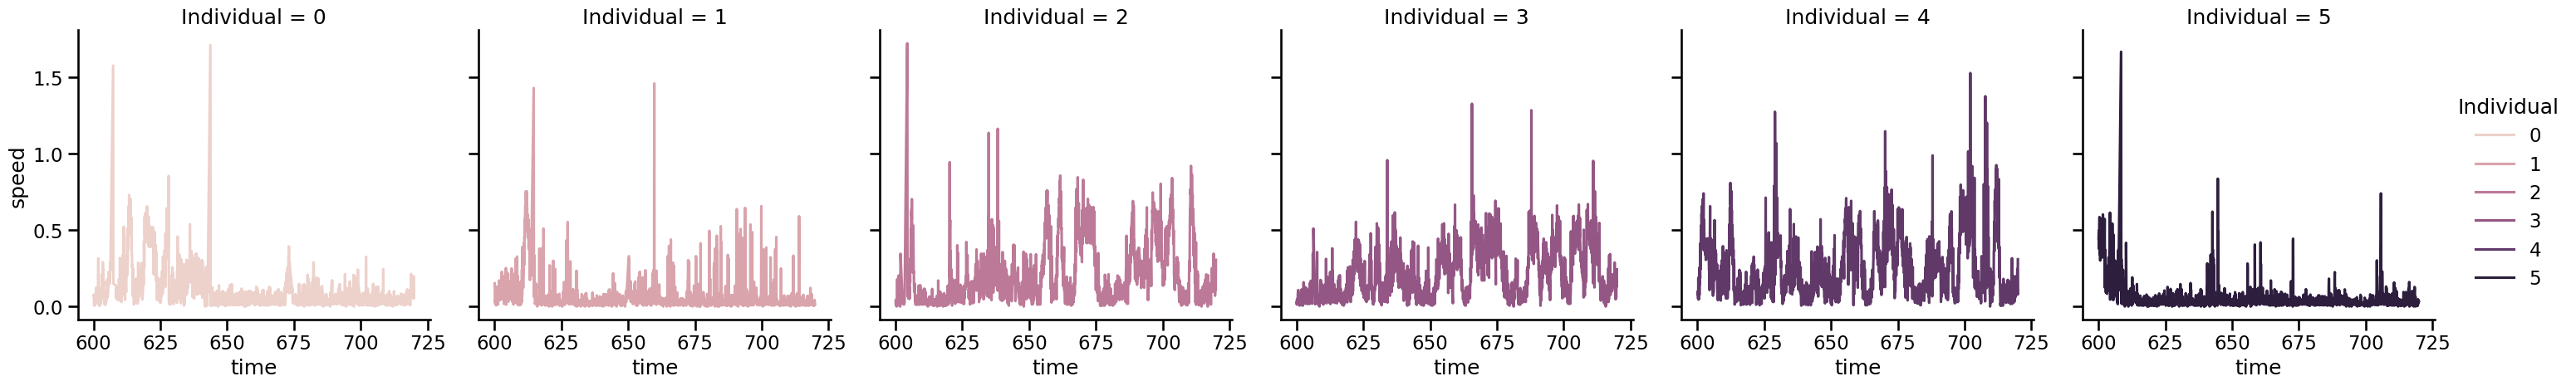

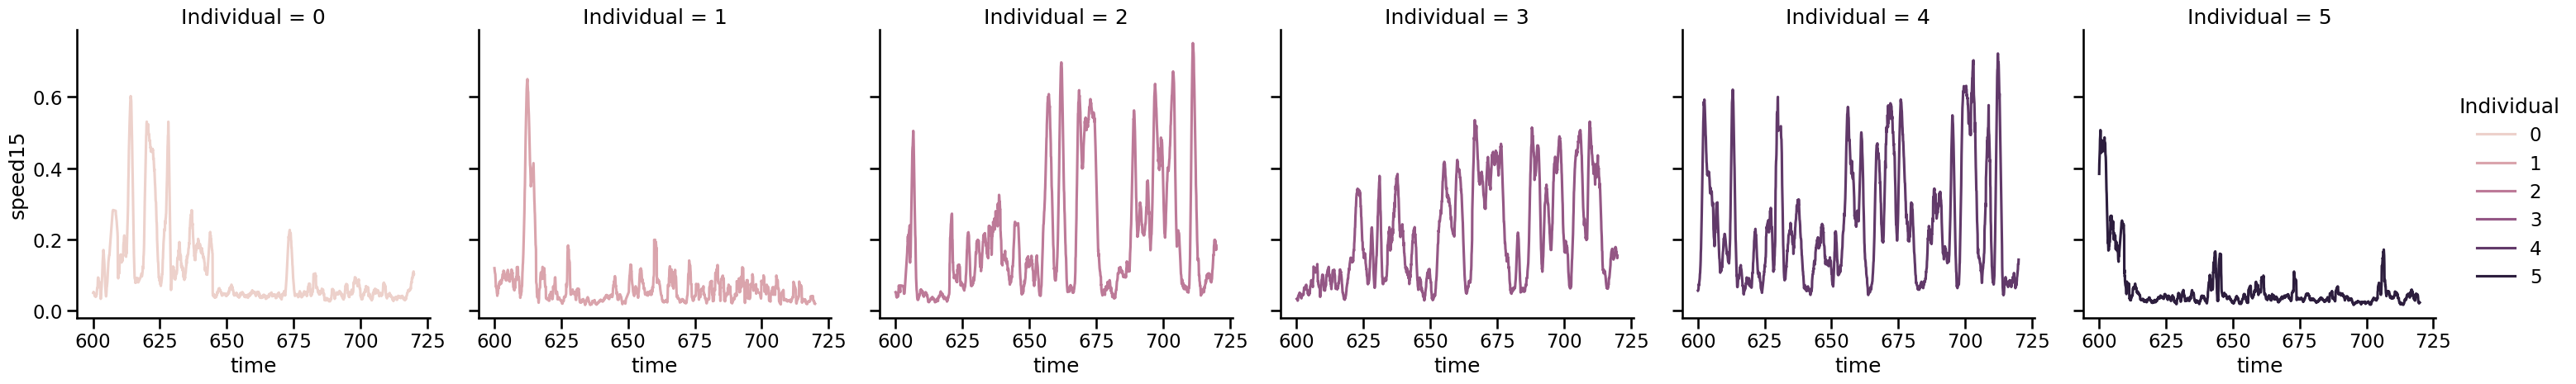

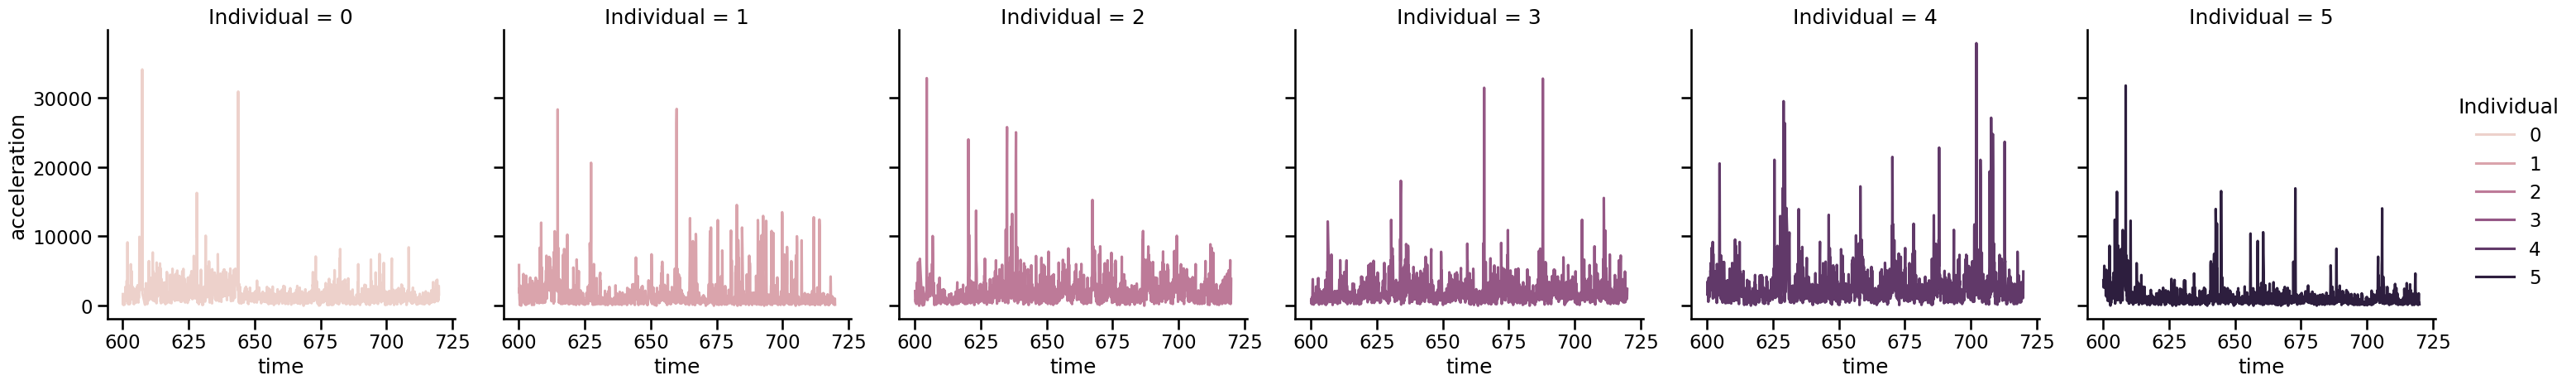

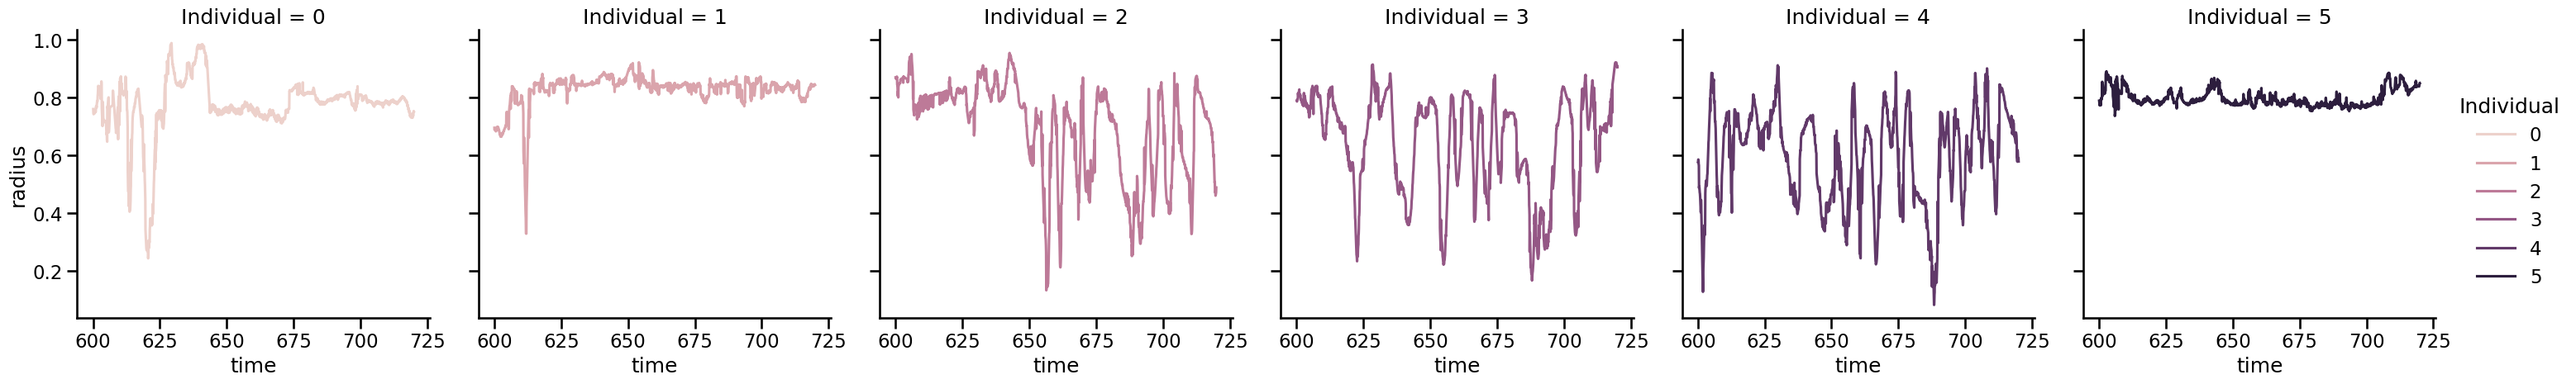

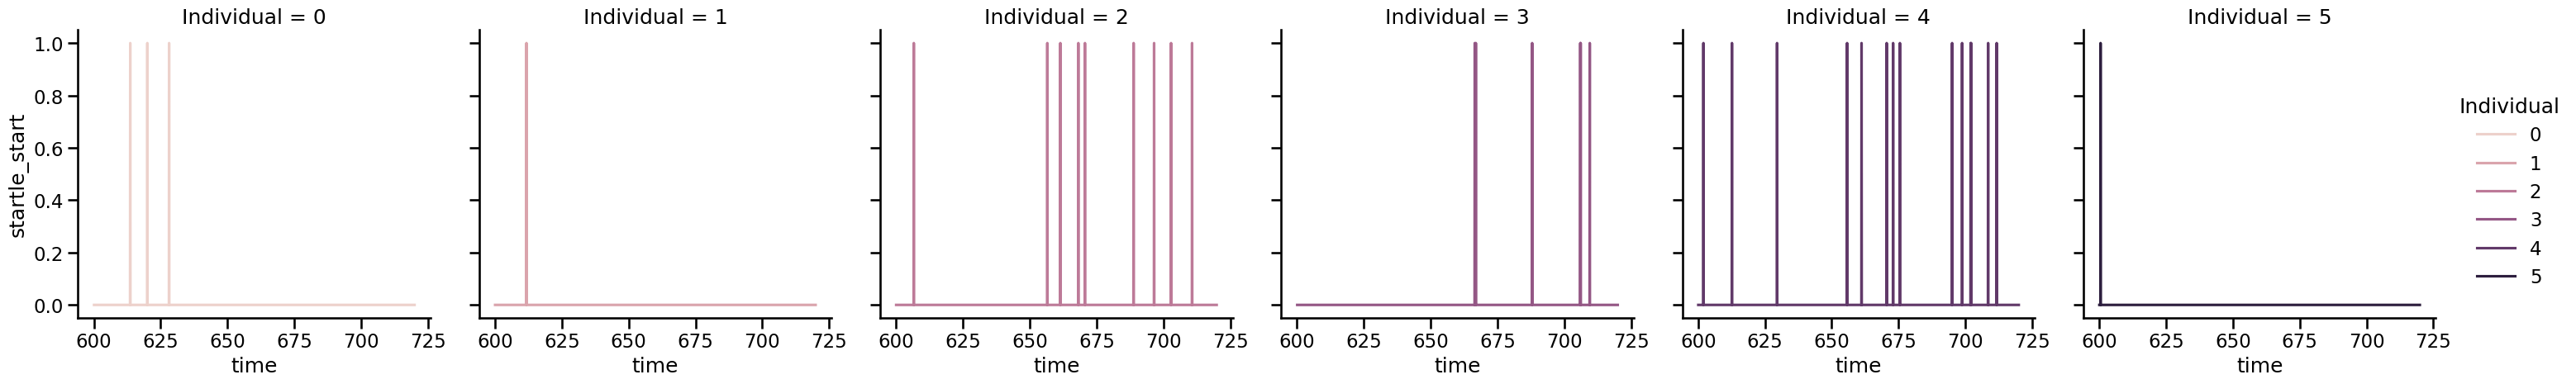

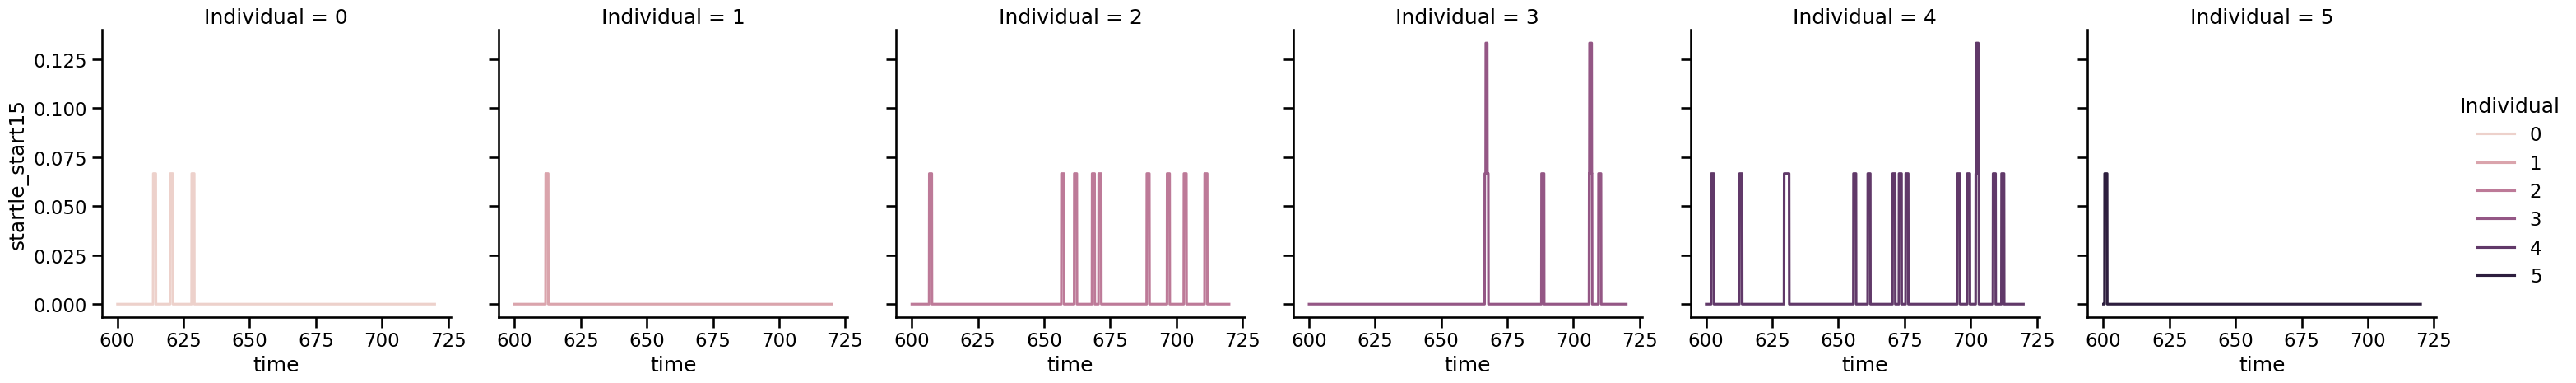

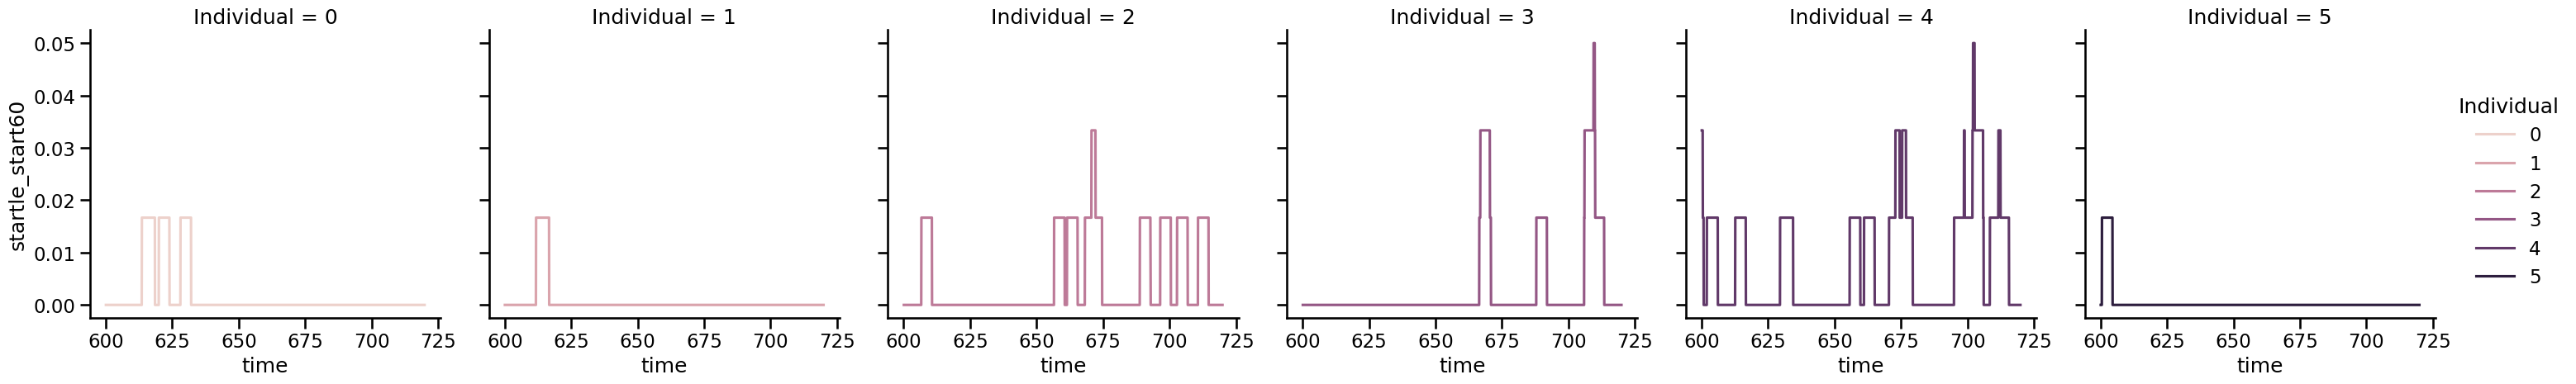

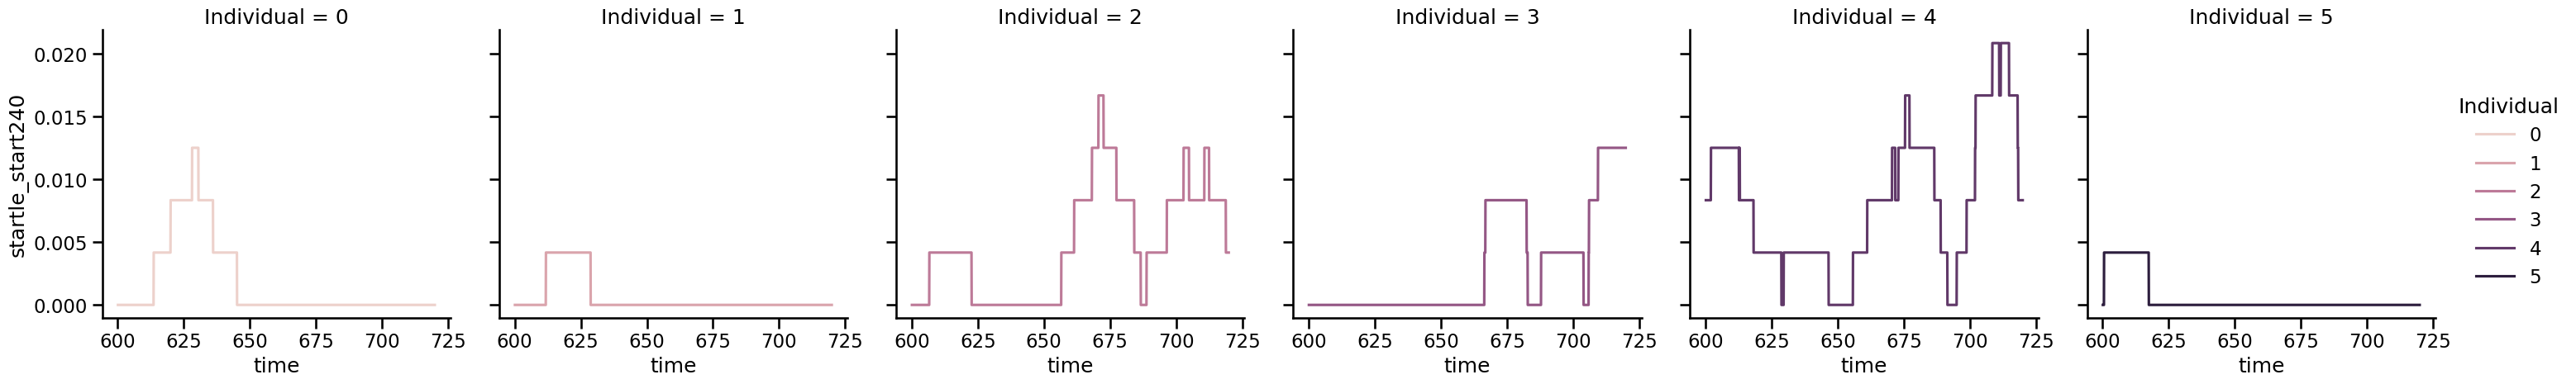

In [53]:
RIVER = "Skagit"
PH = 1
TRIAL = 8
VARIABLES = [
    # "X",
    # "Y",
    "speed",
    "speed15",
    "acceleration",
    # "acceleration0.99",
    "radius",
    "startle_start",
    "startle_start15",
    "startle_start60",
    "startle_start240",
    # "meanneighbordist",
    # "minneighbordist",
]


one_video = df[
    (df["River"] == RIVER) &
    (df["pH"] == PH) &
    (df["Trial"] == TRIAL) &
    (df["time"] > 60 * 10) &
    (df["time"] < 60 * 12) &
    True
    ]

# sns.relplot(data=one_video, x="X", y="Y", hue="time", col="Individual")

for var in VARIABLES:
    p = sns.relplot(data=one_video, x="time", y=var, kind="line", hue="Individual", col="Individual", errorbar=None)